# Chapter 5 — Layers and the transfer matrix: dynamics from a distribution

So far a model has been a single, static object: one probability distribution over whole labelings of a board. Nothing in it "happens". There is no before and after.

Now take a board shaped like a stack of rings: a cylinder. Cut it into its rings, one layer at a time, and ask a modest question: *if I know the labels on one ring, what do I know about the next one?* The answer turns out to be one matrix. Its eigenvalues are numbers you can also measure by sampling the model and watching how quickly two rings forget each other. And on the simplest boards, the ring's loop product does nothing more than a random walk on the group.

This chapter is the bridge of the course. On one side is "a model is a distribution". On the other side is a vector space with an operator acting on it, which physicists would recognize as a quantum system. We will build that operator from the distribution, never assume it.

**What you'll learn**

- How cutting a board into layers turns a model into a chain of matrix multiplications (the transfer matrix).
- Why, on a cylinder, the loop product of a layer performs a random walk on $G$, and what the eigenvalues of that walk mean.
- How the same numbers come out of sampling the model as a black box: two roads to one number.

**Prerequisites:** chapters 1–4. From linear algebra: eigenvalues of symmetric matrices. From probability: Markov chains.

In [1]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.linalg import circulant
from scipy.optimize import minimize_scalar
from scipy.special import ive

from lgt import *
from lgt import viz
from lgt.grid import GridModel

viz.use_style()
rng = np.random.default_rng(5)

## 5.1 Cutting a board into layers

Take a grid with $W$ columns and $N$ rows and wrap it around in both directions. Each row is now a **ring** of $W$ vertices. We call the rows **layers** $V_0,V_1,\dots,V_{N-1}$, with layer indices taken mod $N$, so layer $N$ is layer $0$ again (glossary 5.2).

Every edge is one of two kinds:

- a **layer edge** joins two vertices of the same layer (the edges going around a ring);
- a **step edge** joins a vertex of layer $k$ to the vertex above it in layer $k+1$.

Every face is a square with two layer edges (one in layer $k$, one in layer $k+1$) and two step edges. So the faces sit *between* consecutive layers, in a band we call a **slab**. A **layer labeling** (glossary 5.5) is the restriction of a labeling $U$ to the $W$ layer edges of one layer: an element $a\in\Omega:=G^{W}$.

If you ignore the wrap-around in the vertical direction, the board looks like a cylinder: rings stacked on top of each other, joined by step edges. Below, one layer is drawn in teal and the step edges above it in gold. (Time wraps around too, so the top ring is glued back to the bottom one.)

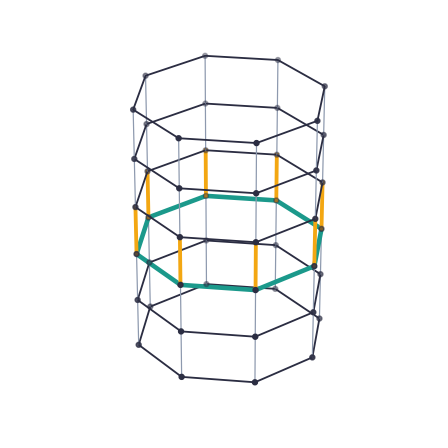

In [2]:
def draw_cylinder(ax, W, N, layer=2):
    ang = 2 * np.pi * np.arange(W + 1) / W
    for k in range(N):
        c = viz.TEAL if k == layer else viz.INK
        ax.plot(np.cos(ang), np.sin(ang), k, color=c, lw=3 if k == layer else 1.2)
        ax.scatter(np.cos(ang[:W]), np.sin(ang[:W]), k, color=viz.INK, s=10)
        if k < N - 1:
            for x in range(W):
                c = viz.GOLD if k == layer else viz.MUTED
                ax.plot([np.cos(ang[x])] * 2, [np.sin(ang[x])] * 2, [k, k + 1], color=c,
                        lw=2.5 if k == layer else 0.8)
    ax.set_box_aspect((1, 1, 1.4)); ax.set_axis_off()

fig = plt.figure(figsize=(5, 5.5))
draw_cylinder(fig.add_subplot(projection="3d"), W=8, N=6)
plt.show()

Each ring (black) is a layer; the vertical segments are step edges. The teal ring is layer 2, and the gold step edges lead from it to layer 3.

**Symmetries.** A **symmetry of a board** (glossary 5.1) is a bijection of the vertices that maps edges to edges and faces to faces. The total cost only looks at face products, so a symmetry of the board is automatically a symmetry of every model on it. Our board has two that matter:

- the **shift** $\tau$ moves every vertex up one layer, $(x,k)\mapsto(x,k+1)$ (glossary 5.3);
- the **flip** $\theta$ turns the stack upside down, $(x,k)\mapsto(x,-k)$ (glossary 5.4).

Let's check both with a few lines of code, together with a bijection that is *not* a symmetry.

In [3]:
def is_symmetry(board, vmap):
    edges = lambda m: sorted(tuple(sorted((m[s], m[t]))) for s, t in board.edges.tolist())
    faces = lambda m: sorted(tuple(sorted({m[v] for v in board.walk_vertices(f)})) for f in board.faces)
    ident = list(range(board.n_vertices))
    return edges(vmap) == edges(ident) and faces(vmap) == faces(ident)

W, N = 4, 6
B = Board.grid(W, N, periodic=True)                    # vertex (x, k) has index x + W*k
vid = lambda x, k: (x % W) + W * (k % N)
shift = [vid(x, k + 1) for k in range(N) for x in range(W)]
flip = [vid(x, -k) for k in range(N) for x in range(W)]
twist = [vid(-x if k == 0 else x, k) for k in range(N) for x in range(W)]  # mirror layer 0 only
print("shift:", is_symmetry(B, shift), "  flip:", is_symmetry(B, flip), "  twist:", is_symmetry(B, twist))

shift: True   flip: True   twist: False


Why do we care? Because of the shift, every slab looks exactly like every other slab. Whatever rule tells us how layer $k$ constrains layer $k+1$, it is the *same* rule for every $k$, just like a time-homogeneous Markov chain uses the same transition matrix at every step. The flip will give that rule a special shape (sections 5.4 and 5.6).

> **Recap.** A layered board splits its vertices into layers $V_0,\dots,V_{N-1}$. Layer edges stay inside a layer, step edges go from one layer to the next, and every face lives in the slab between two consecutive layers. The shift and the flip are symmetries of the board, hence of every model on it.

**Check yourself**

1. On the $W\times N$ torus, how many layer edges, step edges and faces are there in total?

<details><summary>Answer</summary>

$WN$ layer edges ($W$ per layer), $WN$ step edges ($W$ per slab) and $WN$ faces ($W$ per slab).

</details>

2. Why is "mirror only layer 0" not a symmetry?

<details><summary>Answer</summary>

It keeps layer 0's ring intact, but the step edge from $(x,0)$ to $(x,1)$ is sent to a pair $(-x,0)$, $(x,1)$, which is not an edge unless $x\equiv-x$.

</details>

## 5.2 The transfer matrix

This section builds one matrix, $T$, that contains the whole model on the stack. We get there in three small steps: a toy chain, one slab of our board, and then the matrix itself.

### Warm-up: a sum over sequences is a matrix power

Forget boards for a moment. Suppose you have a finite set of states $\Omega$ and a table of nonnegative weights $K(a,b)$, one for every ordered pair of states. Give a *sequence* of states $a_0,a_1,\dots,a_t$ the weight

$$
K(a_0,a_1)\,K(a_1,a_2)\cdots K(a_{t-1},a_t).
$$

If $K$ were a table of transition probabilities, this would be the probability of a path of a Markov chain. Here it is just a weight. Now fix the two ends $a_0$ and $a_t$ and add up the weights of all sequences in between. For $t=2$ this sum is

$$
\sum_{a_1\in\Omega}K(a_0,a_1)\,K(a_1,a_2),
$$

which is exactly the $(a_0,a_2)$ entry of the matrix product $K\cdot K$. By the same reasoning, **summing over all the states in between, for sequences of length $t$, gives the entry $(K^t)(a_0,a_t)$ of the $t$-th matrix power.** This is the same fact you use when you compute $t$-step probabilities of a Markov chain, or count walks of length $t$ in a graph with powers of its adjacency matrix.

One more twist. If the sequence is *cyclic*, meaning it must end where it started ($a_t=a_0$), then adding up over $a_0$ as well gives $\sum_{a_0}(K^t)(a_0,a_0)$, the **trace** $\operatorname{tr}K^t$. Let's check both statements by brute force on a two-state example.

In [4]:
K = np.array([[3.0, 1.0],
              [1.0, 2.0]])                      # weights between two states, called 0 and 1
t_len = 4
seqs = list(itertools.product([0, 1], repeat=t_len + 1))
open_sum = sum(np.prod([K[s[i], s[i + 1]] for i in range(t_len)]) for s in seqs if (s[0], s[-1]) == (0, 1))
cyclic = sum(np.prod([K[s[i], s[i + 1]] for i in range(t_len)]) for s in seqs if s[0] == s[-1])
Kt = np.linalg.matrix_power(K, t_len)
print(f"sequences 0 -> ... -> 1 of length 4: brute force {open_sum:.0f}, matrix power entry {Kt[0, 1]:.0f}")
print(f"cyclic sequences of length 4:        brute force {cyclic:.0f}, trace of K^4 {np.trace(Kt):.0f}")

sequences 0 -> ... -> 1 of length 4: brute force 75, matrix power entry 75
cyclic sequences of length 4:        brute force 175, trace of K^4 175


Matrix powers are a compact way to add up exponentially many products. Now we show that our model on the stack *is* a weighted sequence of this kind, with states = layer labelings.

### One slab

Look at the slab between layer $k$ and layer $k+1$ of the $W\times N$ torus. It contains:

- the $W$ layer edges of layer $k$, carrying the layer labeling $a=(a_0,\dots,a_{W-1})\in\Omega=G^W$;
- the $W$ layer edges of layer $k+1$, carrying $b=(b_0,\dots,b_{W-1})\in\Omega$;
- the $W$ step edges between them, carrying $s=(s_0,\dots,s_{W-1})\in G^W$;
- $W$ faces. Face $x$ is the square between columns $x$ and $x+1$; its four edges are $a_x$, $b_x$, $s_x$ and $s_{x+1}$ (with $s_W=s_0$, since the ring closes).

Here is a slab with $W=3$, unrolled flat, the dashed column being column 0 again.

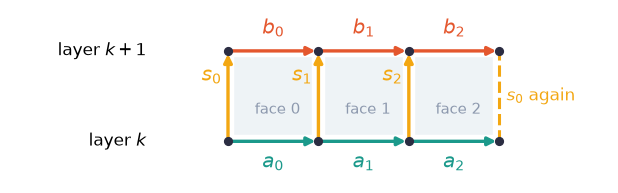

In [5]:
def draw_slab(ax, W=3):
    for x in range(W):
        ax.annotate("", xy=(x + 1, 0), xytext=(x, 0), arrowprops=dict(arrowstyle="-|>", color=viz.TEAL, lw=2.2))
        ax.annotate("", xy=(x + 1, 1), xytext=(x, 1), arrowprops=dict(arrowstyle="-|>", color=viz.CORAL, lw=2.2))
        ax.annotate("", xy=(x, 1), xytext=(x, 0), arrowprops=dict(arrowstyle="-|>", color=viz.GOLD, lw=2.2))
        ax.text(x + 0.5, -0.13, f"$a_{x}$", ha="center", va="top", fontsize=13, color=viz.TEAL)
        ax.text(x + 0.5, 1.13, f"$b_{x}$", ha="center", va="bottom", fontsize=13, color=viz.CORAL)
        ax.text(x - 0.07, 0.72, f"$s_{x}$", ha="right", va="center", fontsize=13, color=viz.GOLD)
        ax.add_patch(plt.Rectangle((x + 0.08, 0.08), 0.84, 0.84, color=viz.PALE, zorder=0))
        ax.text(x + 0.55, 0.35, f"face {x}", ha="center", va="center", fontsize=10, color=viz.MUTED)
    ax.plot([W, W], [0, 1], ls="--", color=viz.GOLD, lw=2)
    ax.text(W + 0.08, 0.5, "$s_0$ again", ha="left", va="center", fontsize=11, color=viz.GOLD)
    ax.text(-0.9, 0.0, "layer $k$", ha="right", va="center", fontsize=11)
    ax.text(-0.9, 1.0, "layer $k+1$", ha="right", va="center", fontsize=11)
    ax.scatter(*np.meshgrid(np.arange(W + 1), [0, 1]), color=viz.INK, zorder=5, s=25)
    ax.set_xlim(-2.4, W + 1.2); ax.set_ylim(-0.45, 1.45); ax.set_aspect("equal"); ax.axis("off")

fig, ax = plt.subplots(figsize=(7, 3))
draw_slab(ax)
plt.show()

Every face of the board lies in exactly one slab, and a face in this slab involves only $a$, $b$ and $s$. So the total cost splits into slab costs, and the weight $e^{-\beta S(U)}$ splits into a **product of slab weights**:

$$
e^{-\beta S(U)}=\prod_{k=0}^{N-1} q(a_k,s_k,a_{k+1}),\qquad q(a,s,b)=\prod_{x=0}^{W-1}e^{-\beta\varphi(\text{face }x)}\ \in\mathbb R_{>0}.
$$

Here $q(a,s,b)$ is the **slab weight**: the weight of one slab whose lower layer carries $a$, whose step edges carry $s$ and whose upper layer carries $b$. On the left, $a_k\in\Omega$ is the *whole* layer labeling of layer $k$ and $s_k\in G^W$ the step labels of slab $k$. So from now on the subscript tells you what is meant: $a_x$ with a column index $x$ is one label of a layer labeling $a$; $a_k$ (or $a_t$) with a layer index is the layer labeling of layer $k$.

For the coin model ($G=\mathbb Z_2$, labels $\pm1$, which are their own inverses) the face product of face $x$ is simply $a_x\,s_{x+1}\,b_x\,s_x$, and $\varphi(f)=1-f$.

### The matrix

The step labels $s$ of a slab appear in that slab's weight and nowhere else. So we can add them up slab by slab, which leaves a weight that depends only on the two neighboring layer labelings. That is the **transfer matrix** (glossary 5.6):

$$
T(a,b)=\sum_{s\in G^W}q(a,s,b),\qquad T\in\mathbb R^{\Omega\times\Omega}.
$$

Its rows and columns are indexed by layer labelings. For the coin model with $W=3$ there are $2^3=8$ of them, so $T$ is $8\times8$. Let's compute one entry by hand first, $T(a,b)$ with $a=b=(+1,+1,+1)$. The face products become $s_xs_{x+1}$, so each face is a defect exactly when $s_x\neq s_{x+1}$. Going through the 8 choices of $s$: 2 of them (all equal) give no defects, and the other 6 give exactly 2 defects. Each defect costs $\varphi(-1)=2$, so

$$
T\big((+,+,+),(+,+,+)\big)=2\cdot1+6\cdot e^{-4\beta}.
$$

In [6]:
def layer_labelings(W):
    """All 2^W coin-model layer labelings, as rows of +-1."""
    return np.array(list(itertools.product([1, -1], repeat=W)))

def coin_transfer_matrix(W, beta):
    A = layer_labelings(W)                      # rows of A also serve as the step labels s
    T = np.zeros((len(A), len(A)))
    for i, a in enumerate(A):
        for j, b in enumerate(A):
            f = a * b * A * np.roll(A, -1, axis=1)          # face x: a_x b_x s_x s_{x+1}, one row per s
            T[i, j] = np.exp(-beta * (1 - f)).prod(axis=1).sum()
    return T

beta = 0.7
T3 = coin_transfer_matrix(3, beta)
print(f"T(+++, +++) from code: {T3[0, 0]:.6f}   by hand: {2 + 6 * np.exp(-4 * beta):.6f}")

T(+++, +++) from code: 2.364860   by hand: 2.364860


### The normalizer $Z$ is a trace

Recall from chapter 2 what a model needs: a weight $e^{-\beta S(U)}$ for every labeling, and the total of all weights,

$$
Z=\sum_{U}e^{-\beta S(U)}\ \in\mathbb R_{>0}
$$

(for a finite group, summing over all labelings $U$). Every probability is a weight divided by $Z$, and every average is a ratio of two such sums. (Chapter 2 divided $Z$ by the number of labelings, to compare with the uniform distribution. That changes $Z$ by a constant factor, which cancels from every probability.)

Computing $Z$ by brute force means visiting all $|G|^{|E|}$ labelings. The transfer matrix replaces this with a matrix power, in three steps.

**Step 1: organize the sum by layers and slabs.** A labeling of the stack is the same thing as a list of $N$ layer labelings $a_0,\dots,a_{N-1}$ together with $N$ lists of step labels $s_0,\dots,s_{N-1}$. Its weight is a product of slab weights, with $a_N=a_0$ because the stack wraps around:

$$
Z=\sum_{a_0,\dots,a_{N-1}}\ \sum_{s_0,\dots,s_{N-1}}\ q(a_0,s_0,a_1)\,q(a_1,s_1,a_2)\cdots q(a_{N-1},s_{N-1},a_0).
$$

**Step 2: sum out the step labels.** The labels $s_k$ appear in factor $k$ and in no other factor, so their sum can be done inside that factor, and it gives $T(a_k,a_{k+1})$ by definition:

$$
Z=\sum_{a_0,\dots,a_{N-1}}T(a_0,a_1)\,T(a_1,a_2)\cdots T(a_{N-1},a_0).
$$

**Step 3: recognize the warm-up.** This is a sum over *cyclic* sequences of states, weighted by $K=T$. So it is a trace:

$$
Z=\operatorname{tr}T^N .
$$

In the smallest case, $N=2$, you can see it directly: $Z=\sum_{a_0,a_1}T(a_0,a_1)\,T(a_1,a_0)=\sum_{a_0}(T^2)(a_0,a_0)=\operatorname{tr}T^2$.

(On boards of dimension 3 or more, some faces lie *inside* a layer. Their cost is then split half-and-half between the two slabs touching that layer, so that $T$ stays symmetric. On our 2D torus every face is in a slab, so no splitting is needed.)

The check: build the model on the $3\times3$ torus, enumerate all $2^{18}$ labelings exactly (chapter 2), and compare $Z$ with $\operatorname{tr}T^3$.

In [7]:
B33 = Board.grid(3, 3, periodic=True)
ex = Model(B33, Z2(), beta).exact()
total_weight = 2.0 ** B33.n_edges * np.exp(ex.log_Z)   # undo chapter 2's division by 2^18
print(f"Z by summing over all 2^18 labelings: {total_weight:.6e}")
print(f"trace of T^3:                         {np.trace(np.linalg.matrix_power(T3, 3)):.6e}")

Z by summing over all 2^18 labelings: 3.762284e+03
trace of T^3:                         3.762284e+03


They agree to every digit. A sum over 262,144 labelings has become the trace of the cube of an $8\times8$ matrix. For a taller board we would only raise $T$ to a higher power, and the matrix stays $8\times8$.

**Why a trace?** Because the stack is periodic: layer $N$ *is* layer $0$, so the sequence of layers must return to where it started. If instead the stack had two separate ends, with the bottom layer fixed to $a$ and the top layer fixed to $b$, the same three steps would give a single matrix entry, $(T^N)(a,b)$. The trace is the periodic version of that.

### Averages are traces too

The same bookkeeping computes averages. Suppose $f:\Omega\to\mathbb R$ is a function of one layer's labeling, and you want $\langle f(a_0)\rangle_\beta$. An average is the sum of (weight × $f$) divided by $Z$, so put the factor $f(a_0)$ into the sum of Step 2. In matrix language, let $D_f\in\mathbb R^{\Omega\times\Omega}$ be the diagonal matrix with the values $f(a)$ on its diagonal. Then $(D_fT)(a_0,a_1)=f(a_0)\,T(a_0,a_1)$, so multiplying by $f(a_0)$ is the same as inserting $D_f$ just before the first $T$:

$$
\sum_{a_0,\dots,a_{N-1}}f(a_0)\,T(a_0,a_1)\cdots T(a_{N-1},a_0)=\operatorname{tr}\big(D_f\,T^N\big).
$$

A second function $g$ of layer $t$ (for $0\le t\le N$) is inserted the same way, as $D_g$ after the first $t$ factors of $T$. Dividing by $Z=\operatorname{tr}T^N$ gives:

> **Rule (averages as traces).** For functions $f,g:\Omega\to\mathbb R$ of a layer labeling, $\langle f(a_0)\,g(a_t)\rangle_\beta=\operatorname{tr}\big(D_f\,T^t\,D_g\,T^{N-t}\big)/\operatorname{tr}T^N$.

Read it as a trip around the stack: measure $f$, go up $t$ slabs, measure $g$, and go the remaining $N-t$ slabs back to the start. Let's check it on the $3\times3$ torus with $f=g=w$, the ring's loop product of a layer: $w(a)=a_0a_1a_2$, the product of its three labels (column indices here). We compare layers 0 and 1.

In [8]:
eidx = B33.meta["edge_index"]
def w_layer(k):
    """Loop product of layer k's ring, for every labeling of the exact enumeration."""
    return np.prod([ex.U[:, eidx[(x + 3 * k, 0)]] for x in range(3)], axis=0)

D_w = np.diag(layer_labelings(3).prod(axis=1))          # multiply by the loop product
mp = np.linalg.matrix_power
print(f"<w(a_0) w(a_1)> by enumeration: {np.sum(ex.p * w_layer(0) * w_layer(1)):.6f}")
print(f"<w(a_0) w(a_1)> by traces:      {np.trace(D_w @ T3 @ D_w @ mp(T3, 2)) / np.trace(mp(T3, 3)):.6f}")

<w(a_0) w(a_1)> by enumeration: 0.266615
<w(a_0) w(a_1)> by traces:      0.266615


### Tall stacks: one eigenvalue wins

First a property we will use constantly: **$T$ is symmetric**, $T(a,b)=T(b,a)$. Swapping the roles of the two layers is the flip of one slab, which maps faces to faces and does not change any cost (it may invert a face product, and the face costs of glossary 4.2 satisfy $\varphi(x^{-1})=\varphi(x)$). For the coin model you can see it directly: the face product $a_x\,s_{x+1}\,b_x\,s_x$ doesn't change if $a$ and $b$ trade places. A real symmetric matrix has real eigenvalues $\lambda_0\ge\lambda_1\ge\cdots$ and an orthonormal basis of eigenvectors.

The trace of a matrix is the sum of its eigenvalues, and the eigenvalues of $T^N$ are the $N$-th powers of those of $T$. So

$$
Z=\operatorname{tr}T^N=\sum_n\lambda_n^N .
$$

Every entry of $T$ is a sum of positive weights. For such a matrix the Perron–Frobenius theorem (the one behind the stationary distribution of a Markov chain) says that the largest eigenvalue $\lambda_0$ is positive and strictly larger than $|\lambda_n|$ for every other $n$. Dividing by $\lambda_0^N$, every other term $(\lambda_n/\lambda_0)^N$ goes to $0$. So as $N$ grows, $\lambda_0$ takes over: $Z\approx\lambda_0^N$, and $\frac1N\log Z\to\log\lambda_0$. In words: **in a tall stack every layer contributes the same factor $\lambda_0$ to the total weight.** You can see it converge.

In [9]:
print("T symmetric:", np.allclose(T3, T3.T))
lam0 = np.linalg.eigvalsh(T3).max()
for N_ in [1, 2, 3, 5, 10, 20]:
    print(f"N = {N_:>2}:  (1/N) log Z = {np.log(np.trace(mp(T3, N_))) / N_:.6f}     log lambda_0 = {np.log(lam0):.6f}")

T symmetric: True
N =  1:  (1/N) log Z = 2.940161     log lambda_0 = 2.740694
N =  2:  (1/N) log Z = 2.764484     log lambda_0 = 2.740694
N =  3:  (1/N) log Z = 2.744260     log lambda_0 = 2.740694
N =  5:  (1/N) log Z = 2.740799     log lambda_0 = 2.740694
N = 10:  (1/N) log Z = 2.740694     log lambda_0 = 2.740694
N = 20:  (1/N) log Z = 2.740694     log lambda_0 = 2.740694


Already at $N=10$ the two agree to six digits. This factor $\lambda_0$ is "the weight per layer", and section 5.4 will divide by it.

> **Recap.** A sum over sequences of products is a matrix power, and a sum over cyclic sequences is a trace. Writing a labeling as layers plus step labels and summing out the step labels gives $Z=\operatorname{tr}T^N$ on a periodic stack (a single entry $(T^N)(a,b)$ with fixed ends). Averages of layer functions are traces with diagonal matrices inserted. In a tall stack $Z\approx\lambda_0^N$: each layer contributes the factor $\lambda_0$.


**Check yourself**

1. In the warm-up, what does $(K^t)(a,b)$ add up?

<details><summary>Answer</summary>

The weights of all sequences of length $t$ that start at $a$ and end at $b$, where a sequence's weight is the product of $K$ over its consecutive pairs.

</details>

2. Compute $T\big((+,+,+),(-,+,+)\big)$ by hand.

<details><summary>Answer</summary>

Now face 0 has product $-s_0s_1$ and faces 1, 2 have $s_1s_2$, $s_2s_0$. The product of all three face products is $-1$, so an odd number of faces are defects: 1 or 3. Going through $s$: 6 choices give one defect and 2 give three. So $T=6e^{-2\beta}+2e^{-6\beta}$.

</details>

3. How big is $T$ for the coin model with $W=10$? For $G=S_3$ with $W=4$?

<details><summary>Answer</summary>

$2^{10}\times2^{10}=1024\times1024$, and $6^4\times6^4=1296\times1296$. The size grows exponentially in the size of a layer, but not with the height of the stack.

</details>

## 5.3 The layer constraint: the ring's loop product does a random walk

Let's look at the $8\times8$ matrix. We sort the layer labelings by their **loop product** $w(a)=a_0a_1a_2$ (chapter 1: the product of the labels around the ring), the four with $w=+1$ first.

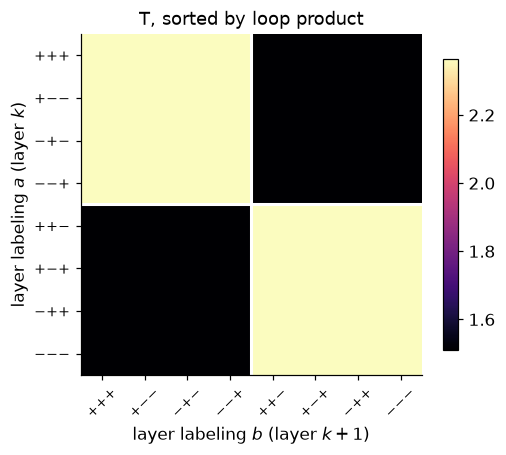

In [10]:
A3 = layer_labelings(3)
w3 = A3.prod(axis=1)
order = np.argsort(-w3, kind="stable")                    # w = +1 first, then w = -1
names = ["".join("+" if v > 0 else "−" for v in a) for a in A3[order]]
fig, ax = plt.subplots(figsize=(5, 4.3))
im = ax.imshow(T3[np.ix_(order, order)], cmap="magma")
ax.axhline(3.5, color="white", lw=2); ax.axvline(3.5, color="white", lw=2)
ax.set_xticks(range(8), names, rotation=45, fontsize=9); ax.set_yticks(range(8), names, fontsize=9)
ax.set(xlabel="layer labeling $b$ (layer $k+1$)", ylabel="layer labeling $a$ (layer $k$)",
       title="T, sorted by loop product")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

Two things stand out. The matrix has only **two distinct entries**. And it is made of four constant blocks: the entry is large when $a$ and $b$ have the *same* loop product, and small when they differ. Everything else about $a$ and $b$ seems to be irrelevant. Why?

### Why $T$ only sees loop products

Take a reframing $h$ that acts only on the vertices of layer $k+1$. It changes the layer labeling $b$ into some other labeling $h\cdot b$. It also changes the step labels touching layer $k+1$, but those are exactly the labels $s$ that $T$ sums over. Reframing doesn't change any face product's cost (chapter 2), and it only *relabels* which $s$ is which in the sum. So the sum is the same:

> **Fact 5.1 (layer constraint).** For every reframing $h$ that acts only on one layer, $T(a,h\cdot b)=T(a,b)$, and likewise $T(h\cdot a,b)=T(a,b)$. So $T(a,b)$ depends only on the classes of $a$ and $b$ (glossary 5.10).

On a ring the class of a layer labeling is determined by its loop product (chapter 1). For the coin model that means: $T(a,b)$ depends only on whether $w(a)=w(b)$. Let's check, using the reframing that flips vertex 1 of the upper layer (which flips the two labels $b_0$ and $b_1$ touching it).

In [11]:
code = lambda rows: ((1 - rows) // 2) @ (2 ** np.arange(3)[::-1])     # row of +-1 -> row index of T
h = np.array([1, -1, 1])                                             # flip vertex 1 only
hb = A3 * h * np.roll(h, -1)                                         # b_x -> h_x b_x h_{x+1}
print("T(a, h.b) == T(a, b) for all a, b:", np.allclose(T3[:, code(hb)], T3))
same, diff = T3[0, 0], T3[0, code(np.array([[-1, 1, 1]]))[0]]
print(f"the two entries: same loop product {same:.4f}, different loop product {diff:.4f}")

T(a, h.b) == T(a, b) for all a, b: True
the two entries: same loop product 2.3649, different loop product 1.5096


### Shrinking $T$ to a $2\times2$ matrix

Since only $w$ matters, collapse each block. Write $T_{\text{same}}$ and $T_{\text{diff}}$ for the two entries printed above. If the current layer has loop product $w$, the total weight of moving to *some* next labeling with loop product $w'$ is the block entry times the 4 labelings in that block:

$$
\tilde T=\begin{pmatrix}4\,T_{\text{same}} & 4\,T_{\text{diff}}\\ 4\,T_{\text{diff}} & 4\,T_{\text{same}}\end{pmatrix},
$$

rows and columns indexed by $w\in\lbrace +1,-1\rbrace$. Divide each row by its sum and you get a matrix of transition probabilities: the probability that the next layer's loop product equals or differs from this one's.

In [12]:
Tt = 4 * np.array([[same, diff], [diff, same]])
P = Tt / Tt.sum(axis=1, keepdims=True)
print("transition probabilities for the loop product (rows: from +1, -1; columns: to +1, -1):")
print(np.round(P, 4))
print(f"probability of keeping w: {P[0, 0]:.4f}    formula (1 + tanh(beta)^3) / 2 = {(1 + np.tanh(beta) ** 3) / 2:.4f}")

transition probabilities for the loop product (rows: from +1, -1; columns: to +1, -1):
[[0.6104 0.3896]
 [0.3896 0.6104]]
probability of keeping w: 0.6104    formula (1 + tanh(beta)^3) / 2 = 0.6104


Where does that formula come from? Use the freedom of Fact 5.1: reframe layer by layer from the bottom up so that every step label becomes $+1$. (This is a tree normal form whose tree contains the step edges; on a torus one slab is left over, which we ignore for now.) With all $s_x=+1$, the face products of a slab are just $f_x=a_xb_x$, so $b_x=a_xf_x$, and multiplying around the ring:

$$
w(b)=w(a)\cdot f_0f_1\cdots f_{W-1}.
$$

The face products of a slab are independent, each $+1$ with probability $\frac{1}{1+e^{-2\beta}}$ (this is Fact 2.8 of chapter 2, and its average is $\tanh\beta$). So $f_0\cdots f_{W-1}$ has average $r=(\tanh\beta)^W$, and it is $+1$ with probability $(1+r)/2$.

> **Fact 5.2 (the ring's walk).** Going up one layer, the ring's loop product is multiplied by the product of $W$ independent random face products, each with distribution proportional to $e^{-\beta\varphi}$. The sequence $w(a_0),w(a_1),w(a_2),\dots$ is a random walk on $G$. For the coin model it keeps its value with probability $(1+r)/2$ and flips with probability $(1-r)/2$, where $r=(\tanh\beta)^W$.

Here is that walk, read off from samples of the actual model (using the fast sampler of chapter 4) on tori with $N=64$ layers and three ring lengths.

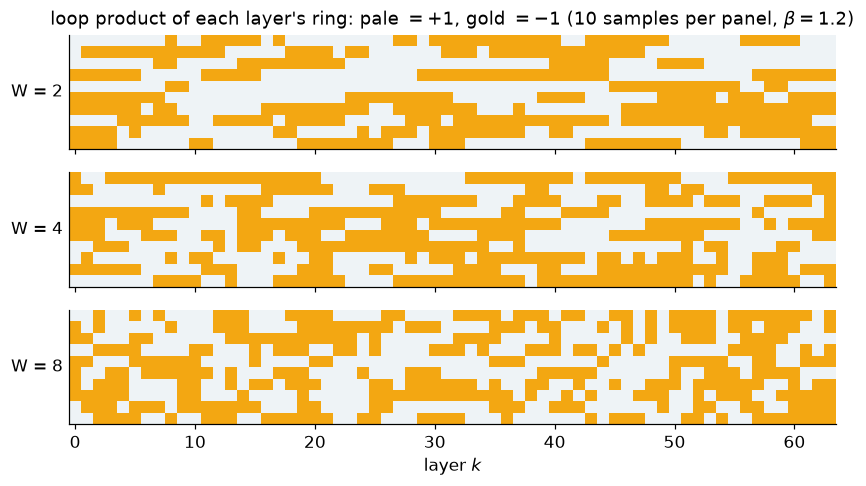

In [13]:
def ring_walks(W, N, beta, n_samples, rng, gap=20):
    M = GridModel((W, N), Z2(), beta).hot_start(rng)
    M.sweep(rng, 300)
    out = []
    for _ in range(n_samples):
        M.sweep(rng, gap)
        out.append(M.U[0].prod(axis=0))          # loop product of every layer's ring
    return np.array(out)

walks = {W: ring_walks(W, 64, 1.2, 1000, rng, gap=5) for W in [2, 4, 8]}
fig, axs = plt.subplots(3, 1, figsize=(9, 4.6), sharex=True)
for ax, W in zip(axs, [2, 4, 8]):
    ax.imshow(walks[W][::100], cmap=ListedColormap([viz.GOLD, viz.PALE]), aspect="auto", vmin=-1, vmax=1)
    ax.set_yticks([]); ax.set_ylabel(f"W = {W}", rotation=0, ha="right", va="center")
axs[-1].set_xlabel("layer $k$")
axs[0].set_title(r"loop product of each layer's ring: pale $=+1$, gold $=-1$ (10 samples per panel, $\beta=1.2$)")
plt.show()

Each row is one sample: a sequence of 64 values, flipping now and then like a telegraph signal. The longer the ring, the more often it flips, because more faces get a chance to be defects.

This is worth pausing on. Summing the model over everything except the layers' loop products leaves *a sum over paths* $w_0\to w_1\to\cdots\to w_{N-1}\to w_0$ of a random walk on $G$, each path weighted by its step probabilities. A weighted sum over paths is what physicists call a **path integral**. Here it is not a metaphor: it is a random walk you can sample.

> **Recap.** $T(a,b)$ doesn't change if either layer is reframed, so it only sees the classes of the layers. On a ring those are given by the loop product, so $T$ collapses to a small matrix on $G$, which (after normalizing rows) is the transition matrix of a random walk: going up one layer multiplies the loop product by $W$ independent face products.

**Check yourself**

1. For the coin model at $\beta=1.2$, what is the probability that the loop product flips between consecutive layers, for $W=2$ and $W=8$?

<details><summary>Answer</summary>

$\tanh1.2\approx0.834$. For $W=2$, $r\approx0.695$ and the flip probability is $(1-r)/2\approx0.15$. For $W=8$, $r\approx0.234$ and it is about $0.38$.

</details>

2. At $\beta=0$ what does the walk do?

<details><summary>Answer</summary>

Every face product is uniform, so their product is uniform: the loop product jumps to a fresh uniform value at every layer. No memory at all.

</details>

## 5.4 How fast do layers forget? Eigenvalues

Here is the question that will give us the most important number of the chapter: **if you know the loop product at layer 0, how much do you know about it at layer $t$?**

### Iterating the walk by hand

The answer is in the powers $P^t$ of the transition matrix: $(P^t)(w,w')$ is the probability of going from $w$ to $w'$ in $t$ steps (the warm-up of 5.2 again). For a $2\times2$ matrix we can compute $P^t$ exactly, using two special vectors. Write $P$ as

$$
P=\frac12\begin{pmatrix}1+r & 1-r\\ 1-r & 1+r\end{pmatrix}.
$$

Multiply it by the vectors $u_0=(1,1)$ and $u_1=(1,-1)$:

$$
P\,u_0=u_0,\qquad P\,u_1=r\,u_1 .
$$

So $u_0$ and $u_1$ are **eigenvectors**, with **eigenvalues** $1$ and $r$: $P$ does not mix them, it only scales them. Read as functions of the loop product, $u_0$ is the constant function and $u_1$ is the function $w$ itself. Any vector is a combination of the two, for example the starting distribution "certainly $+1$":

$$
(1,0)=\tfrac12u_0+\tfrac12u_1 .
$$

(A distribution is usually multiplied by $P$ from the left. Here $P$ is symmetric, so left and right give the same vector, and $P^t(1,0)^{\top}$ is the first column of $P^t$, whose first entry is $(P^t)(+1,+1)$.) Applying $P$ a total of $t$ times multiplies the $u_0$ part by $1^t$ and the $u_1$ part by $r^t$:

$$
P^t(1,0)^{\top}=\tfrac12u_0+\tfrac12r^tu_1=\big(\tfrac12+\tfrac12r^t,\ \tfrac12-\tfrac12r^t\big).
$$

The first entry is the answer:

$$
\Pr(w_t=+1\mid w_0=+1)=\frac12+\frac12\,r^t .
$$

The constant part, $\frac12$, is where the walk ends up when it has forgotten everything. The memory of the start is the second part, and it **shrinks by the factor $r$ at every layer**. The eigenvalue $r$ *is* the rate of forgetting.

Let's check this against the samples from the previous section: the fraction of pairs of layers $t$ apart whose loop products agree.

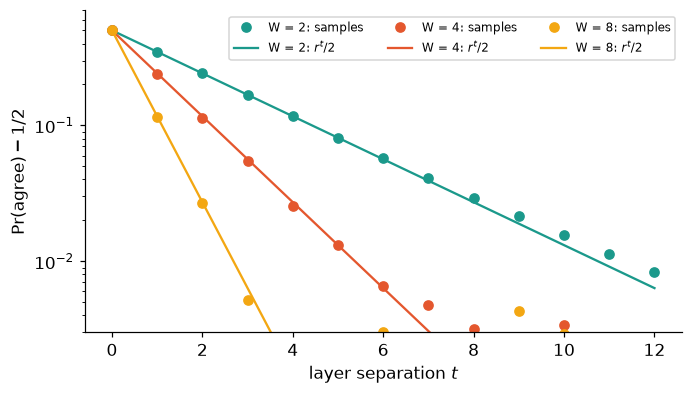

In [14]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ts = np.arange(0, 13)
for W, c in zip([2, 4, 8], [viz.TEAL, viz.CORAL, viz.GOLD]):
    agree = [np.mean(walks[W] == np.roll(walks[W], -t, axis=1)) for t in ts]
    r_W = np.tanh(1.2) ** W
    ax.semilogy(ts, np.array(agree) - 0.5, "o", color=c, label=f"W = {W}: samples")
    ax.semilogy(ts, 0.5 * r_W ** ts, "-", color=c, lw=1.5, label=fr"W = {W}: $r^t/2$")
ax.set(xlabel="layer separation $t$", ylabel=r"$\Pr(\mathrm{agree}) - 1/2$", ylim=(3e-3, 0.7))
ax.legend(fontsize=8, ncol=3, loc="upper right")
plt.show()

On this logarithmic scale each "memory" curve is a straight line, and its slope is $\log r$. A longer ring has a smaller $r$, so a steeper line: it forgets faster. Once the remaining memory is below about half a percent, it is smaller than the sampling noise, and the points scatter around the line instead of following it (for $W=8$ that happens after only a few layers).

### Levels: rates instead of factors

Exponential decay is easier to talk about as a rate. Write $r=e^{-E_1}$, so that

$$
r^t=e^{-E_1t},\qquad E_1=-\log r .
$$

$E_1$ is "how much memory is lost per layer". For the coin model, $E_1=-\log(\tanh\beta)^W=-W\log\tanh\beta$.

In general we don't normalize $T$ into a probability matrix first, so we define the rates directly from the eigenvalues of $T$. $T$ is symmetric, so its eigenvalues are real. Order them $\lambda_0\ge\lambda_1\ge\cdots$. The **levels** (glossary 5.8) are

$$
E_n=-\log\frac{\lambda_n}{\lambda_0}\ \ge0 .
$$

Dividing by $\lambda_0$ is what normalizing does: $\lambda_0$ is the overall weight per layer, and it cancels from every probability. For the coin model you can see this exactly. Every row of $\tilde T$ has the same sum, so the constant vector $u_0$ is an eigenvector of $\tilde T$ with that row sum as eigenvalue, and that is $\lambda_0$ (checked below). Then $P=\tilde T/\lambda_0$, so the eigenvalues of $P$ are those of $\tilde T$ divided by $\lambda_0$: $1$ and $r=\lambda_1/\lambda_0$. So $E_0=0$ always, and the **gap** $E_1$ is the decay rate of the slowest-forgetting memory. A small gap means long memory; a big gap means fast forgetting.

### What about the other six eigenvalues?

The full $T$ for $W=3$ is $8\times8$, so it has 8 eigenvalues, not 2. Let's look at all of them.

In [15]:
ev = np.sort(np.linalg.eigvalsh(T3))[::-1]
print("eigenvalues of the 8x8 T:", np.round(ev, 6) + 0.0)
print(f"lambda_1 / lambda_0 = {ev[1] / ev[0]:.6f}     r = tanh(beta)^3 = {np.tanh(beta) ** 3:.6f}")
print(f"lambda_0 = {ev[0]:.6f}     row sum of the 2x2 matrix = {Tt[0].sum():.6f}")

eigenvalues of the 8x8 T: [15.497733  3.42115   0.        0.        0.        0.        0.
  0.      ]
lambda_1 / lambda_0 = 0.220752     r = tanh(beta)^3 = 0.220752
lambda_0 = 15.497733     row sum of the 2x2 matrix = 15.497733


Two of them are the eigenvalues of the small matrix $\tilde T$: on a function that is constant on each class, $T$ acts exactly like $\tilde T$, because each block has 4 equal entries. The other six are **exactly zero**. The reason is Fact 5.1. Take any function $g$ of a layer labeling that adds up to zero over each class, for example $g(b)=b_0-b_1$ (which flips sign under the reframing of vertex 1). Then

$$
(Tg)(a)=\sum_bT(a,b)\,g(b)=\sum_{\text{classes }c}T(a,c)\sum_{b\in c}g(b)=0,
$$

because $T(a,b)$ is the same number $T(a,c)$ for every $b$ in a class $c$. Such functions form a subspace of dimension $8-2=6$: the 8 values of $g$ only have to satisfy one linear condition per class, and there are 2 classes. Every vector in it is an eigenvector with eigenvalue $0$, which accounts for the six zeros. So $T$ **erases** everything about a layer except its class. Only functions of the loop product survive one step, and those are what the levels describe. This is why glossary 5.8 says to restrict $T$ to reframing-invariant functions.

In [16]:
g = A3[:, 0] - A3[:, 1]                                          # b_0 - b_1, not an invariant
print("T applied to g = b_0 - b_1:", np.round(T3 @ g, 10))
for W_ in [2, 3, 4, 6]:
    lam = np.sort(np.linalg.eigvalsh(coin_transfer_matrix(W_, beta)))[::-1]
    print(f"W={W_}: nonzero eigenvalues {np.sum(lam > 1e-9)},  E1 = {-np.log(lam[1] / lam[0]):.4f},  "
          f"-W log tanh(beta) = {-W_ * np.log(np.tanh(beta)):.4f}")

T applied to g = b_0 - b_1: [0. 0. 0. 0. 0. 0. 0. 0.]
W=2: nonzero eigenvalues 2,  E1 = 1.0071,  -W log tanh(beta) = 1.0071
W=3: nonzero eigenvalues 2,  E1 = 1.5107,  -W log tanh(beta) = 1.5107
W=4: nonzero eigenvalues 2,  E1 = 2.0143,  -W log tanh(beta) = 2.0143
W=6: nonzero eigenvalues 2,  E1 = 3.0214,  -W log tanh(beta) = 3.0214


For every ring length, only 2 eigenvalues are nonzero, and the gap matches $-W\log\tanh\beta$. **The gap is proportional to the length of the ring**: keeping a loop of length $W$ "remembered" from layer to layer costs an amount proportional to $W$.

### A warning about signs

We took $\log$ of eigenvalue ratios without worrying. That needs every relevant eigenvalue to be positive. (Zero eigenvalues are harmless: they belong to the erased functions, which we have just set aside.) A negative eigenvalue would make the memory *alternate in sign* from layer to layer ($r^t$ with $r<0$), and no decay rate could describe it. For our models this never happens. The property that guarantees it is called **flip-positivity**, and it is important enough to get its own section (5.6).

> **Recap.** An eigenvector of the walk is a function that one step only rescales; its eigenvalue is the factor. Memory of the start decays like $(\lambda_1/\lambda_0)^t=e^{-E_1t}$, so the gap $E_1$ is the rate of forgetting. $T$ erases every non-invariant function (eigenvalue 0), so only functions of the loop product matter. For the coin model $E_1=-W\log\tanh\beta$, and flip-positivity guarantees the logarithm makes sense.

**Check yourself**

1. Verify $P\,u_1=r\,u_1$ by multiplying out.

<details><summary>Answer</summary>

First entry: $\frac12\big((1+r)-(1-r)\big)=r$. Second entry: $\frac12\big((1-r)-(1+r)\big)=-r$. So $Pu_1=(r,-r)=r\,u_1$.

</details>

2. Suppose we allowed a *negative* stiffness, $\beta=-0.7$, with $W=3$. What is $\lambda_1/\lambda_0$, and what goes wrong?

<details><summary>Answer</summary>

$\tanh(-0.7)^3\approx-0.22$. The memory $r^t$ alternates in sign and $-\log$ of a negative number is undefined. Flip-positivity fails for negative stiffness (with odd $W$), and the derived picture of section 5.8 breaks down (section 5.6 shows this failure in detail).

</details>

3. Why does the gap grow with $W$?

<details><summary>Answer</summary>

The ring's loop product flips whenever an odd number of the $W$ faces in a slab are defects. More faces mean more chances, so the walk forgets faster.

</details>

## 5.5 Two roads to one number

We computed the gap from the cost function: build $T$, take eigenvalues. Now forget the cost. Suppose someone hands you a **black box** that produces random labelings of the cylinder from some model, and nothing else. Can you get the same number?

Yes: section 5.4 already said how. Memory decays like $e^{-E_1t}$, so measure memory. Write $w_k=w(a_k)\in\lbrace\pm1\rbrace$ for the loop product of layer $k$'s ring and define the **layer correlation**

$$
C(t)=\big\langle w_k\,w_{k+t}\big\rangle_\beta,\qquad C:\lbrace 0,\dots,N\rbrace\to\mathbb R ,
$$

which by the shift symmetry does not depend on $k$.

### The prediction, step by step

On a periodic stack two layers $t$ apart are joined two ways: $t$ slabs going up and $N-t$ slabs going the rest of the way round. With the matrices of 5.2 the average is

$$
C(t)=\frac{\operatorname{tr}\big(D_w\,T^t\,D_w\,T^{N-t}\big)}{\operatorname{tr}T^N},
$$

where $D_w$ is the diagonal matrix that multiplies by the loop product (the rule of 5.2 with $f=g=w$). Now compute the trace in a basis of eigenvectors of $T$. Recall that the trace of a matrix $M$ can be computed in any orthonormal basis, as $\sum_v v^{\top}Mv$; so a basis vector with $Mv=cv$ contributes exactly $c$. For the space of functions on $\Omega$ ($2^W$-dimensional) take:

- $u_0$, the constant function $1$, with $Tu_0=\lambda_0u_0$;
- $u_1$, the function $w$ itself, with $Tu_1=\lambda_1u_1$ (these are the vectors $(1,1)$ and $(1,-1)$ of the walk, now read as functions of the whole layer labeling);
- the remaining $2^W-2$ basis vectors: erased functions $g$, with $Tg=0$ (5.4).

(Divide each by its length to make them orthonormal; that doesn't change what they contribute.) An erased $g$ contributes $0$, because the first matrix to act on it, $T^{N-t}$, kills it (for $0<t<N$). Multiplying by $w$ swaps the other two, since $w^2=1$: $D_wu_0=u_1$ and $D_wu_1=u_0$. Now follow $u_0$ through $M=D_w\,T^t\,D_w\,T^{N-t}$, from right to left: $T^{N-t}$ scales it by $\lambda_0^{N-t}$, $D_w$ turns it into $u_1$, $T^t$ scales by $\lambda_1^t$, and $D_w$ turns it back into $u_0$. So $Mu_0=\lambda_0^{N-t}\lambda_1^t\,u_0$. Starting from $u_1$ instead gives $Mu_1=\lambda_1^{N-t}\lambda_0^t\,u_1$. Adding both and dividing by $\operatorname{tr}T^N=\lambda_0^N+\lambda_1^N$ (the zero eigenvalues add nothing):

$$
C(t)=\frac{\lambda_0^{N-t}\lambda_1^{t}+\lambda_1^{N-t}\lambda_0^{t}}{\lambda_0^N+\lambda_1^N}=\frac{e^{-E_1t}+e^{-E_1(N-t)}}{1+e^{-E_1N}} .
$$

Two exponentials appear because a periodic stack can be traversed both ways round. For $t$ much smaller than $N$, $C(t)\approx e^{-E_1t}$: **the correlation between layers decays at a rate equal to the gap.**

First a sanity check of this formula against exact enumeration on the $3\times3$ torus, where $N=3$ and $t=1$:

In [17]:
eidx = B33.meta["edge_index"]
w_layer = lambda k: np.prod([ex.U[:, eidx[(x + 3 * k, 0)]] for x in range(3)], axis=0)
C1_exact = float(np.sum(ex.p * w_layer(0) * w_layer(1)))
r = np.tanh(beta) ** 3
print(f"C(1) by enumeration: {C1_exact:.6f}    by the formula: {(r + r ** 2) / (1 + r ** 3):.6f}")

C(1) by enumeration: 0.266615    by the formula: 0.266615


Now road 2 for real. We sample the coin model on a $4\times16$ torus at $\beta=1.6$ with the chapter 4 sampler, record every layer's loop product, and average $w_kw_{k+t}$ over all samples and all starting layers $k$. The cost function is used only inside the sampler, which we treat as the black box.

In [18]:
W5, N5, beta5 = 4, 16, 1.6
M = GridModel((W5, N5), Z2(), beta5).hot_start(rng)
M.sweep(rng, 500)
ws = np.array([(M.sweep(rng), M.U[0].prod(axis=0))[1] for _ in range(20000)])   # (samples, N)
per_sample = np.stack([np.mean(ws * np.roll(ws, -t, axis=1), axis=1) for t in range(N5 + 1)], 1)
blocks = per_sample.reshape(100, -1, N5 + 1).mean(axis=1)                         # binning (ch. 4)
C_hat, C_err = blocks.mean(axis=0), blocks.std(axis=0, ddof=1) / np.sqrt(len(blocks))

def C_model(t, E1, N):
    return (np.exp(-E1 * t) + np.exp(-E1 * (N - t))) / (1 + np.exp(-E1 * N))

def fit_E1(C, err, N):
    t = np.arange(1, N)
    return minimize_scalar(lambda E: np.sum(((C[t] - C_model(t, E, N)) / err[t]) ** 2),
                           bounds=(0.01, 3), method="bounded").x

In [19]:
E1_road1 = -W5 * np.log(np.tanh(beta5))
E1_road2 = fit_E1(C_hat, C_err, N5)
boot = [fit_E1(blocks[i].mean(axis=0), C_err, N5)
        for i in (rng.integers(0, len(blocks), len(blocks)) for _ in range(200))]
print(f"road 1 (eigenvalues of T):       E1 = {E1_road1:.4f}")
print(f"road 2 (sampling, black box):    E1 = {E1_road2:.4f} ± {np.std(boot):.4f}")

road 1 (eigenvalues of T):       E1 = 0.3263
road 2 (sampling, black box):    E1 = 0.3361 ± 0.0058


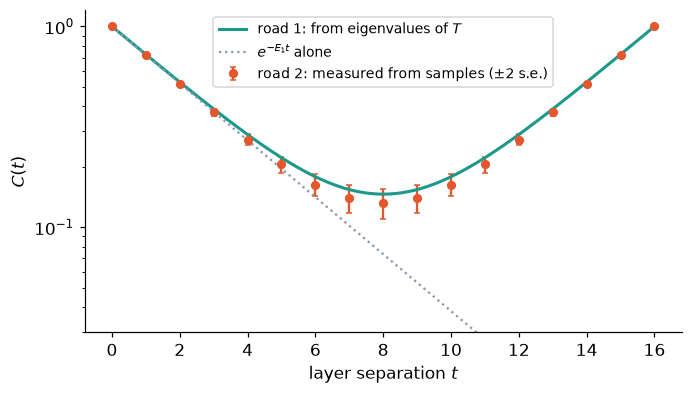

In [20]:
t = np.arange(N5 + 1)
tt = np.linspace(0, N5, 300)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.errorbar(t, C_hat, yerr=2 * C_err, fmt="o", color=viz.CORAL, ms=5, capsize=2,
            label="road 2: measured from samples (±2 s.e.)")
ax.plot(tt, C_model(tt, E1_road1, N5), color=viz.TEAL, lw=2, label="road 1: from eigenvalues of $T$")
ax.plot(tt, np.exp(-E1_road1 * tt), color=viz.MUTED, ls=":", label=r"$e^{-E_1 t}$ alone")
ax.set(xlabel="layer separation $t$", ylabel="$C(t)$", yscale="log", ylim=(0.03, 1.2))
ax.legend(fontsize=9)
plt.show()

The dots (sampling) lie within their error bars of the teal curve (eigenvalues), though all of them sit slightly below it. That common shift is not 15 separate discrepancies: neighbouring points come from the same samples and move together. The fitted gap, $E_1=0.336\pm0.006$ against $0.326$, is about 1.7 standard errors away, which is agreement within the statistical error. For small $t$ both follow the dotted straight line $e^{-E_1t}$ on this log scale; past the middle of the stack the correlation climbs back up, because the layers are approaching each other the other way round the periodic stack.

**Why this matters.** Road 2 never used the cost function: it needed only *samples* of the distribution, plus a way to cut the board into layers with a shift and a flip. This is the answer to a question from the very start of the course: *what do you need, besides the distribution, to extract dynamics?* Only the layering and its symmetries. The cost function is merely one convenient way of writing the distribution down.

> **Recap.** The correlation between layers $t$ apart decays like $e^{-E_1t}$ (with a mirror term on a periodic stack). Measuring that decay from samples gives the gap without ever looking at the cost. Road 1 (eigenvalues) and road 2 (sampling) agree within the sampling error.

**Check yourself**

1. With $E_1\approx0.33$, how many layers apart must two rings be before their correlation drops below 1%?

<details><summary>Answer</summary>

$e^{-0.33t}<0.01$ needs $t>\ln100/0.33\approx14$. On a stack of only 16 layers you'd never see that, because the mirror term takes over first.

</details>

2. The correlation length (glossary 4.7) measures how fast correlations decay with distance. How is it related to the gap?

<details><summary>Answer</summary>

$C(t)\approx e^{-t/\xi}$ with $\xi=1/E_1$: the correlation length in the layer direction is the reciprocal of the gap.

</details>

## 5.6 Flip-positivity

Twice already we needed every eigenvalue of $T$ to be nonnegative: to take logarithms in 5.4, and for $C(t)$ to decay instead of oscillating in 5.5. This section explains the property behind that, **flip-positivity**. It is worth the time: it is also what turns functions on the board into the vector space of a quantum system (5.8), and it is one of the properties the Millennium problem demands of the limit in chapter 6.

### Two ways to put a mirror in the stack

The flip $\theta$ turns the stack upside down. There are two natural places to put the mirror:

- **through a layer:** layer $0$ stays where it is, and layer $k$ goes to layer $-k$;
- **between two layers:** the mirror sits in the middle of slab 0, so layers $0$ and $1$ swap, and layer $k$ goes to layer $1-k$. The step edges of slab 0 are cut in half by the mirror and turned around.

Either way the mirror splits the periodic stack into an **upper half** and a **lower half**, and $\theta$ swaps them. On a periodic stack the mirror has a second copy halfway round, so we take $N$ even. Through a layer, the upper half is layers $0,1,\dots,N/2$ with the edges among them (the two mirror layers $0$ and $N/2$ belong to both halves). Between layers, the upper half is layers $1,\dots,N/2$ with the edges among them; the step edges of slabs $0$ and $N/2$, which the mirrors cut, belong to neither half.

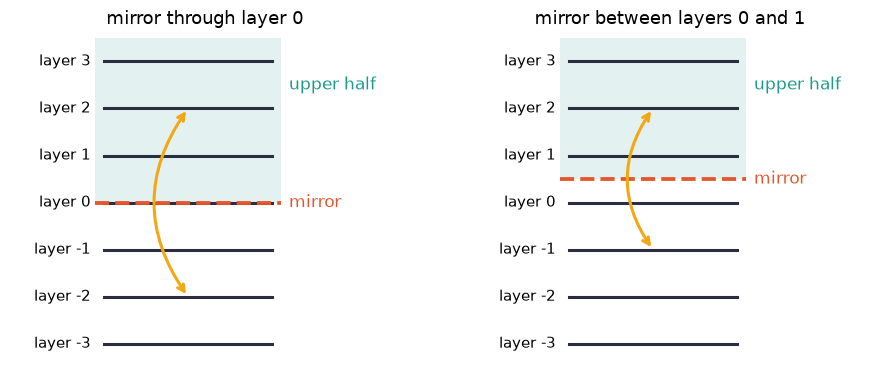

In [21]:
def draw_mirror(ax, between, ks=range(-3, 4)):
    for k in ks:
        ax.plot([0, 4], [k, k], color=viz.INK, lw=2)
        ax.text(-0.3, k, f"layer {k}", ha="right", va="center", fontsize=10)
    m = 0.5 if between else 0.0
    ax.fill_between([-0.2, 4.2], m, 3.5, color=viz.TEAL, alpha=0.12, lw=0)
    ax.plot([-0.2, 4.2], [m, m], color=viz.CORAL, ls="--", lw=2.5)
    ax.text(4.4, m, "mirror", color=viz.CORAL, va="center", fontsize=11)
    ax.text(4.4, 2.5, "upper half", color=viz.TEAL, va="center", fontsize=11)
    t = 2
    ax.annotate("", xy=(2, 2 * m - t), xytext=(2, t),
                arrowprops=dict(arrowstyle="<->", color=viz.GOLD, lw=2, connectionstyle="arc3,rad=0.35"))
    ax.set(xlim=(-2.2, 7), ylim=(-3.6, 3.6), title="mirror between layers 0 and 1" if between else "mirror through layer 0")
    ax.axis("off")

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
draw_mirror(axs[0], between=False); draw_mirror(axs[1], between=True)
plt.show()

The gold arrows join layer 2 to its mirror image: layer $-2$ on the left, layer $-1$ on the right. Notice the number of slabs between a layer and its image. Through a layer it is always **even** ($2t$). Between layers it is always **odd** ($2t-1$). That difference will matter.

### The definition

Write $E_{\text{upper}}$ for the edges of the upper half, and let $F$ be any function of their labels, $F:G^{E_{\text{upper}}}\to\mathbb C$. Its mirror image $\theta F=F\circ\theta$ is the same function applied to the mirrored labeling, so it depends only on the lower half. **Flip-positivity** (glossary 5.7) says:

$$
\big\langle\,\overline{\theta F}\;F\,\big\rangle_\beta\ \ge\ 0\qquad\text{for every function }F\text{ of the upper half.}
$$

In words: *a quantity measured on the top half and the same quantity measured on its mirror image are never, on average, anti-aligned.* For a real $F$ this says that $F$ and its mirror image have a nonnegative average product.

This is not automatic. Averages of products of two *different* functions can be negative, of course. The claim is about a function and its own mirror image, and it is a real restriction on the model.

### The single-layer case is linear algebra

Take the simplest upper-half function, a real function $f:\Omega\to\mathbb R$ of one layer: $F=f(a_t)$ (so the complex conjugate does nothing). Its mirror image is $f$ of the mirrored layer, which is $p$ slabs away, with $p=2t$ (mirror through a layer) or $p=2t-1$ (mirror between layers). By the trace rule of 5.2,

$$
\big\langle\theta F\;F\big\rangle_\beta=\frac{\operatorname{tr}\big(D_f\,T^{p}\,D_f\,T^{N-p}\big)}{\operatorname{tr}T^N}.
$$

(The model is shift-invariant, so only the separation $p$ between the two layers matters.) Write $T$ in its orthonormal eigenvectors $v_0,v_1,\dots$ (5.2): $T^p=\sum_m\lambda_m^{\,p}\,v_mv_m^{\top}$ and $T^{N-p}=\sum_n\lambda_n^{\,N-p}\,v_nv_n^{\top}$. Substituting, and using $\operatorname{tr}(D_fv_mv_m^{\top}D_fv_nv_n^{\top})=(v_n^{\top}D_fv_m)(v_m^{\top}D_fv_n)=(v_m^{\top}D_fv_n)^2$ ($D_f$ is diagonal, hence symmetric), the numerator becomes

$$
\sum_{m,n}\lambda_m^{\,p}\,\lambda_n^{\,N-p}\,\big(v_m^{\top}D_fv_n\big)^2 .
$$

Each term is a square times $\lambda_m^p\lambda_n^{N-p}$. Since $N$ is even, $p$ and $N-p$ are both even (mirror through a layer) or both odd (mirror between layers). Even powers are nonnegative whatever the signs of the eigenvalues. Odd powers are nonnegative for sure only if no eigenvalue is negative. So:

> **Fact 5.3 (flip-positivity for one layer).** Let $T$ be symmetric with positive entries, and $N$ even. For the mirror through a layer, $\langle\theta F\,F\rangle_\beta\ge0$ for every single-layer $F$, automatically. For the mirror between layers, $\langle\theta F\,F\rangle_\beta\ge0$ for every single-layer $F$ if $T$ has no negative eigenvalue; if $T$ does have a negative eigenvalue, it fails for some single-layer $F$ once the stack is tall enough.

Why the failure: on a tall stack the terms with $n=0$ dominate, and they add up to $\lambda_0^{N-p}\sum_m\lambda_m^{\,p}(v_m^{\top}D_fv_0)^2$. By Perron–Frobenius $v_0$ has positive entries, so you can choose $f=v_m/v_0$ (entrywise) for an eigenvector $v_m$ with $\lambda_m<0$. Then $D_fv_0=v_m$, the sum is just $\lambda_m^{\,p}<0$ for odd $p$, and the average is negative.

So the between-layers flip is the demanding one, and **"$T$ has nonnegative eigenvalues" is what flip-positivity says about single layers.**

### Watching it fail

Negative stiffness is the easy way to break it: a model with $\beta<0$ *prefers* defects. Take the coin model with $W=3$ and $\beta=-0.7$. The favourite slab now has all 3 of its faces as defects, an *odd* number, and an odd number of defects in a slab flips the ring's loop product (Fact 5.2). So the loop product tends to flip at every layer. Neighbouring layers become anti-aligned.

Use $F=w(a_1)$, the loop product of layer 1. The mirror between layers 0 and 1 turns it into $w(a_0)$, so flip-positivity requires $\langle w(a_0)\,w(a_1)\rangle_\beta\ge0$. Let's compute it with the trace rule on a stack of $N=8$ layers, for both signs of $\beta$, and for several separations $p$.

In [22]:
def flip_overlap(T, f, p, N):
    """<f(a_0) f(a_p)> on a periodic stack of N layers, by the trace rule."""
    D = np.diag(f)
    return np.trace(D @ mp(T, p) @ D @ mp(T, N - p)) / np.trace(mp(T, N))

w3_ = layer_labelings(3).prod(axis=1)
for b in [0.7, -0.7]:
    Tb = coin_transfer_matrix(3, b)
    vals = "  ".join(f"p={p}: {flip_overlap(Tb, w3_, p, 8):+.4f}" for p in [1, 2, 3, 4])
    ev_ = np.linalg.eigvalsh(Tb); nz = ev_[np.abs(ev_) > 1e-9][::-1]
    print(f"beta = {b:+.1f}   nonzero eigenvalues of T: {np.round(nz, 3)}   {vals}")

beta = +0.7   nonzero eigenvalues of T: [15.498  3.421]   p=1: +0.2208  p=2: +0.0488  p=3: +0.0113  p=4: +0.0047
beta = -0.7   nonzero eigenvalues of T: [1033.487 -228.144]   p=1: -0.2208  p=2: +0.0488  p=3: -0.0113  p=4: +0.0047


At $\beta=+0.7$ every overlap is positive. At $\beta=-0.7$ one eigenvalue of $T$ is negative, and the overlaps for odd separations ($p=1,3$, the between-layers mirror) are negative, exactly as Fact 5.3 predicts. Even separations stay positive.

Is this an artifact of matrices? Ask the black box: sample the $\beta=-0.7$ model directly with the Metropolis rule of chapter 4, and measure the average product of neighbouring layers' loop products.

In [23]:
Bneg = Board.grid(3, 8, periodic=True)
chain = Model(Bneg, Z2(), beta=-0.7).metropolis(rng, n_samples=3000, burn_in=200)
eneg = Bneg.meta["edge_index"]
w_rows = np.stack([np.prod([chain[:, eneg[(x + 3 * k, 0)]] for x in range(3)], axis=0) for k in range(8)], 1)
measured = np.mean(w_rows * np.roll(w_rows, -1, axis=1))
print(f"sampled <w(a_k) w(a_k+1)> at beta=-0.7: {measured:+.3f}    trace rule: {flip_overlap(coin_transfer_matrix(3, -0.7), w3_, 1, 8):+.3f}")

sampled <w(a_k) w(a_k+1)> at beta=-0.7: -0.224    trace rule: -0.221


The samples agree: neighbouring layers really are anti-aligned. With such a model, section 5.4's levels make no sense ($-\log$ of a negative ratio), and the derived system of section 5.8 can't be built.

### Why it holds for our models: a sum of squares

For $\beta\ge0$ it never fails, and for the coin model we can see exactly why. Write one face's weight, for a face product $f=\pm1$. Since $e^{\beta f}=\cosh(\beta f)+\sinh(\beta f)$, and $\cosh$ is even while $\sinh$ is odd, $e^{\beta f}=\cosh\beta+f\sinh\beta$. So:

$$
e^{-\beta(1-f)}=e^{-\beta}\big(\cosh\beta+f\,\sinh\beta\big).
$$

Multiply this over the $W$ faces of a slab and expand the product: $2^W$ terms, each picking, for every face, either $\cosh\beta$ or $f\sinh\beta$. Now sum over the step labels $s$. A step label $s_x$ appears in two faces, $x-1$ and $x$. If a term picks $f\sinh\beta$ in exactly one of them, that term is $s_x$ times something not involving $s_x$, and summing over $s_x=\pm1$ gives $(+1)+(-1)=0$: the term dies. If it picks both, $s_x$ appears squared, $s_x^2=1$, and it survives. So a term survives only if, for every $x$, faces $x-1$ and $x$ are picked alike; going around the ring, that means all faces alike. That leaves just two terms: "pick $\cosh\beta$ everywhere", and "pick $f\sinh\beta$ everywhere". In the second, the product of the $W$ face products $a_x\,s_{x+1}\,b_x\,s_x$ is $w(a)\,w(b)$ times $\prod_xs_x^2=1$. Neither surviving term depends on $s$, so each of the $2^W$ choices of $s$ contributes the same, and

$$
T(a,b)=\big(2e^{-\beta}\big)^W\Big(\cosh^W\!\beta\;+\;\sinh^W\!\beta\;w(a)\,w(b)\Big).
$$

In matrix form, with $\mathbf 1$ the all-ones vector and $w$ the vector of loop products,

$$
T=c_0\,\mathbf 1\mathbf 1^{\top}+c_1\,w\,w^{\top},\qquad c_0=(2e^{-\beta}\cosh\beta)^W,\quad c_1=(2e^{-\beta}\sinh\beta)^W .
$$

The vectors $\mathbf 1$ and $w$ are orthogonal ($\mathbf 1^{\top}w=\sum_aw(a)=0$, since half the labelings have $w=+1$), and each has squared length $2^W$. So $T\mathbf 1=2^Wc_0\,\mathbf 1$ and $Tw=2^Wc_1\,w$, while $T$ kills every vector orthogonal to both. That explains everything we saw in 5.3 and 5.4 at once: two distinct entries, only $\mathbf 1$ and $w$ survive, all other eigenvalues are zero, $\lambda_0=2^Wc_0$, $\lambda_1=2^Wc_1$, and $\lambda_1/\lambda_0=c_1/c_0=\tanh^W\!\beta$. And for any vector $f$,

$$
f^{\top}Tf=c_0\Big(\sum_a f(a)\Big)^2+c_1\Big(\sum_a w(a)f(a)\Big)^2,
$$

a **sum of squares** with coefficients $c_0,c_1$. When $\beta\ge0$ both coefficients are nonnegative, so $f^{\top}Tf\ge0$ for every $f$; taking $f$ to be an eigenvector shows that $T$ can never have a negative eigenvalue. When $\beta<0$ and $W$ is odd, $c_1<0$, and that is the failure we just watched.

In [24]:
for b in [0.7, -0.7]:
    c0, c1 = (2 * np.exp(-b) * np.cosh(b)) ** 3, (2 * np.exp(-b) * np.sinh(b)) ** 3
    closed = c0 * np.ones((8, 8)) + c1 * np.outer(w3_, w3_)
    print(f"beta = {b:+.1f}: closed form matches T: {np.allclose(closed, coin_transfer_matrix(3, b))},   c0 = {c0:.4f}, c1 = {c1:+.4f}")

beta = +0.7: closed form matches T: True,   c0 = 1.9372, c1 = +0.4276
beta = -0.7: closed form matches T: True,   c0 = 129.1859, c1 = -28.5180


The same mechanism works for every group. Above, we expanded the weight of one face in two special functions of the face product, $1$ and $f$. For a general $G$ the special functions are the **characters** of $G$ (for the coin model, $1$ and $f$; for the circle, the functions $e^{in\theta}$, $n\in\mathbb Z$, that 5.7 will use as eigenfunctions of the ring's walk). For the standard face cost every coefficient of that expansion is nonnegative when $\beta\ge0$. For the circle, the expansion is $e^{\beta\cos\theta}=\sum_nI_n(\beta)\,e^{in\theta}$, with the Bessel numbers $I_n(\beta)\ge0$ we will meet again in 5.7. Nonnegative coefficients make the weight across the mirror a sum of "(something about the top half) × (the same thing about the bottom half)", which is a sum of squares. This argument, done carefully for *all* upper-half functions, not just single layers, is the theorem of Osterwalder and Seiler (1978).

> **Fact 5.4 (flip-positivity of our models; Osterwalder–Seiler).** For the standard face costs of glossary 4.2 (including the coin and circle costs), any compact label group, any dimension and any $\beta\ge0$, the model on a periodic grid with an even number of layers is flip-positive for the mirror between layers, for every function of the upper half. In particular $T$ has no negative eigenvalues. (For the mirror through a layer, the single-layer case is automatic, as Fact 5.3 showed; we won't need more than that.)

We don't prove Fact 5.4 here; the coin-model computation above is the single-layer case of it.

In [25]:
th = np.linspace(-np.pi, np.pi, 7)
n_ = np.arange(-30, 31)
series = np.real(np.exp(1j * np.outer(th, n_)) @ ive(n_, 2.0)) * np.exp(2.0)  # sum_n I_n(2) e^{in theta}
print("circle expansion reproduces e^{beta cos theta}:", np.allclose(series, np.exp(2.0 * np.cos(th))))
print("smallest coefficient I_n(2), n = 0..30:", f"{(ive(np.arange(31), 2.0) * np.exp(2.0)).min():.2e}", "(all positive)")

circle expansion reproduces e^{beta cos theta}: True
smallest coefficient I_n(2), n = 0..30: 3.89e-33 (all positive)


### What flip-positivity buys: an inner product

Here is the reason flip-positivity is central rather than technical. For two functions $F,F'$ of the upper half, define

$$
\langle F,F'\rangle_\theta=\big\langle\,\overline{\theta F}\;F'\,\big\rangle_\beta\ \in\mathbb C .
$$

This is linear in $F'$ and conjugate-linear in $F$. Swapping $F$ and $F'$ conjugates it (apply the symmetry $\theta$ inside the average, and use $\theta\theta=$ identity). And flip-positivity says exactly that $\langle F,F\rangle_\theta\ge0$. So it is an **inner product** on functions of the upper half, except that some nonzero functions may have length zero. Throw those away (formally: take the quotient by them), and what is left is a genuine inner-product space, built from nothing but the distribution and the mirror.

For single-layer functions, take the mirror between layers 0 and 1, and $F=f(a_1)$, $F'=g(a_1)$, so $\theta F=f(a_0)$. The trace rule gives $\langle F,F'\rangle_\theta=\operatorname{tr}(D_f\,T\,D_g\,T^{N-1})/\operatorname{tr}T^N$. On a tall stack $T^{N-1}\approx\lambda_0^{N-1}v_0v_0^{\top}$ and $\operatorname{tr}T^N\approx\lambda_0^N$ (5.2), so this tends to $(D_fv_0)^{\top}T(D_gv_0)/\lambda_0$. For the coin model $v_0=\mathbf 1/\sqrt{2^W}$ is constant, so the inner product is proportional to $f^{\top}Tg$. The functions of length zero are those with $f^{\top}Tf=0$. For a matrix with no negative eigenvalues that forces $Tf=0$ (expand $f$ in eigenvectors), so they are exactly the functions $T$ erases: the non-invariant ones of 5.4. What survives are the functions of the loop product. That is the 2-dimensional space we have been working in all along, now obtained from the flip.

In [26]:
G_flip = T3 / np.linalg.eigvalsh(T3).max()        # the flip inner product on single-layer functions
print("rank of the flip inner product on the 8 single-layer functions:", np.linalg.matrix_rank(G_flip, tol=1e-9))
print("its eigenvalues (all >= 0):", np.round(np.linalg.eigvalsh(G_flip), 6) + 0.0)

rank of the flip inner product on the 8 single-layer functions: 2
its eigenvalues (all >= 0): [0.       0.       0.       0.       0.       0.       0.220752 1.      ]


In general, the vector space of a quantum system is constructed exactly this way: functions of the upper half, with the flip inner product, modulo the functions of length zero. The transfer matrix then acts on it as a positive operator. This is the Osterwalder–Schrader construction (named in the dictionary). It is also why flip-positivity is one of the requirements in the Millennium problem (chapter 6): it is an inequality between averages, so it survives limits, and with it the inner product survives too.

> **Recap.** A mirror through a layer or between two layers swaps the upper and lower halves of the stack. Flip-positivity says a function of the upper half and its mirror image never have a negative average product. For single layers it means $T$ has no negative eigenvalue; it fails for negative stiffness, as sampling confirms. For our models it holds because the weight across the mirror is a sum of squares with nonnegative coefficients. Its payoff is an inner product on functions of the upper half: the vector space of the derived system.

**Check yourself**

1. Why is the through-a-layer mirror "automatically" positive for single-layer functions, even at negative stiffness?

<details><summary>Answer</summary>

A layer and its mirror image are an even number $2t$ of slabs apart (and $N-2t$ is even too). Even powers of real eigenvalues are nonnegative, so every term $\lambda_m^{2t}\lambda_n^{N-2t}(v_m^\top D_fv_n)^2$ is nonnegative.

</details>

2. Coin model with $W=4$ and $\beta=-0.7$: does the single-layer test pass?

<details><summary>Answer</summary>

Yes: $c_1=(2e^{-\beta}\sinh\beta)^4\ge0$ because the power is even, so $T$ is still a sum of squares. With 4 faces per slab, the favourite slab (all faces defects) has an even number of defects, so it no longer flips the loop product.

</details>

3. What is $\langle F,F\rangle_\theta$ for a constant function $F=c$?

<details><summary>Answer</summary>

$\langle\bar c\,c\rangle_\beta=|c|^2$, which is $>0$ for $c\neq0$. Constants always have positive length; for the coin model the constant function is (up to normalization) the eigenvector $v_0$ of $T$.

</details>

## 5.7 The circle: free motion on a group

Now let the labels be angles, $G=U(1)$, with face cost $\varphi(\theta)=1-\cos\theta$. Fact 5.2 still holds: the ring's loop product $w\in U(1)$ is a random walk on the circle, and each step adds $W$ independent angles, each with density proportional to $e^{\beta\cos\theta}$.

A random walk on a circle is diagonalized by the functions $\chi_n(w)=e^{in w}$, $n\in\mathbb Z$ (the characters of $U(1)$). One step multiplies $\chi_n$ by the average of $e^{in\theta}$ over one step. For one face that average is a ratio of Bessel functions, $I_n(\beta)/I_0(\beta)$, so

$$
\frac{\lambda_n}{\lambda_0}=\Big(\frac{I_n(\beta)}{I_0(\beta)}\Big)^W,\qquad E_n=-W\log\frac{I_n(\beta)}{I_0(\beta)} .
$$

For a stiff model each face angle is small and roughly Gaussian with variance $1/\beta$, so one step is roughly Gaussian with variance $W/\beta$, and $\lambda_n/\lambda_0\approx e^{-Wn^2/(2\beta)}$:

$$
E_n\approx\frac{W}{2\beta}\,n^2 .
$$

The levels lie on a **parabola**. Let's check this against an honest matrix: replace the circle by $K=64$ equally spaced angles, build the $64\times64$ transfer matrix of the walk, and take its eigenvalues.

In [27]:
def circle_levels_matrix(W, beta, K=64):
    p = np.exp(beta * np.cos(2 * np.pi * np.arange(K) / K)); p /= p.sum()   # one face
    step = p.copy()
    for _ in range(W - 1):                                                   # W faces in a slab
        step = np.real(np.fft.ifft(np.fft.fft(step) * np.fft.fft(p)))
    ev = np.sort(np.linalg.eigvalsh(circulant(step)))[::-1][:15]           # the top few levels
    return -np.log(ev / ev[0])

def circle_levels_bessel(W, beta, n):
    return -W * np.log(ive(n, beta) / ive(0, beta))

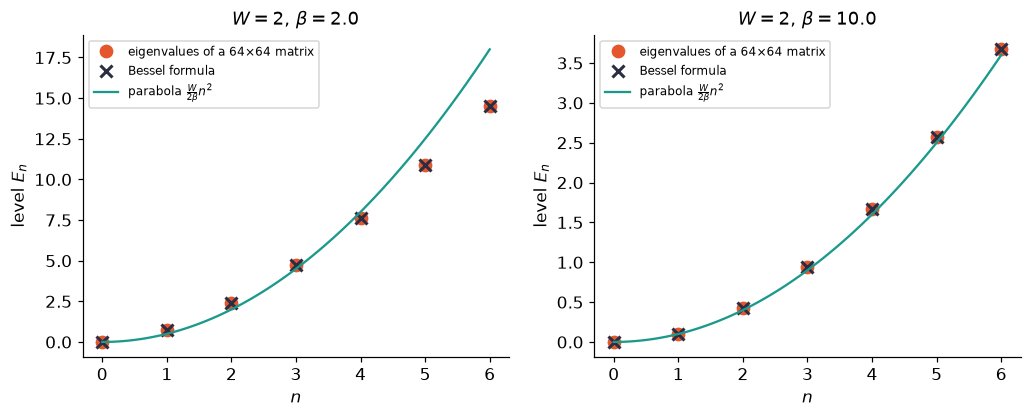

In [28]:
n = np.arange(0, 7)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
for ax, b in zip(axs, [2.0, 10.0]):
    Em = circle_levels_matrix(2, b)
    ax.plot(n, Em[[0] + [2 * k - 1 for k in n[1:]]], "o", color=viz.CORAL, ms=8, label="eigenvalues of a 64×64 matrix")
    ax.plot(n, circle_levels_bessel(2, b, n), "x", color=viz.INK, ms=8, mew=2, label="Bessel formula")
    nn = np.linspace(0, 6, 100)
    ax.plot(nn, 2 / (2 * b) * nn ** 2, color=viz.TEAL, label=r"parabola $\frac{W}{2\beta}n^2$")
    ax.set(title=fr"$W=2$, $\beta={b}$", xlabel="$n$", ylabel="level $E_n$")
    ax.legend(fontsize=8)
plt.show()

Each eigenvalue except the first comes twice, for $n$ and $-n$ (the walk can't tell clockwise from counterclockwise), so we plot every second one. Matrix and formula agree. At $\beta=10$ the levels sit right on the parabola; at $\beta=2$ they bend below it for large $n$, where the Gaussian approximation is too crude.

A parabola of levels $E_n\propto n^2$ is famous: it is the spectrum of a free particle moving on a circle. Physicists call it a **rotor**. Here it was never put in. It came out of a distribution over labelings of a cylinder.

And the walk itself? Below are a few samples of the actual $U(1)$ model on a $4\times64$ torus at $\beta=4$. For each sample we follow the angle $w_k$ of every layer's loop product and draw it continuously (adding $2\pi$ whenever it wraps), starting from $0$.

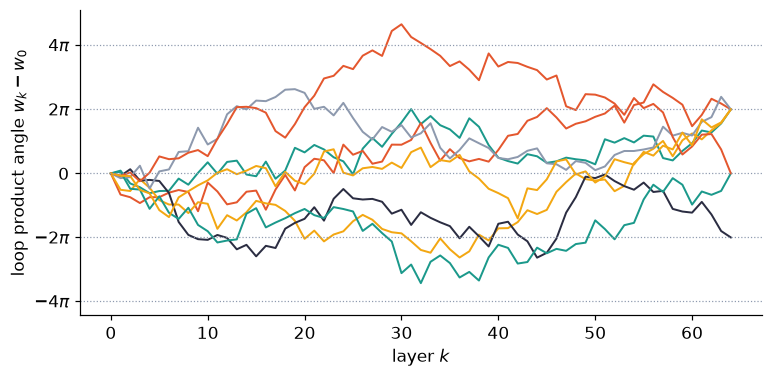

In [29]:
M = GridModel((4, 64), U1(), 4.0).hot_start(rng)
M.sweep(rng, 600)
fig, ax = plt.subplots(figsize=(8, 3.6))
for i in range(8):
    M.sweep(rng, 60)
    ang = np.unwrap(np.angle(M.U[0].prod(axis=0)))
    ax.plot(np.r_[ang, ang[0] + 2 * np.pi * np.round((ang[-1] - ang[0]) / (2 * np.pi))] - ang[0], lw=1.3)
for m in (-2, -1, 0, 1, 2):
    ax.axhline(2 * np.pi * m, color=viz.MUTED, lw=0.8, ls=":")
ks = np.arange(-2, 3)
ax.set(xlabel="layer $k$", ylabel=r"loop product angle $w_k - w_0$", yticks=2 * np.pi * ks,
       yticklabels=[r"$-4\pi$", r"$-2\pi$", "0", r"$2\pi$", r"$4\pi$"])
plt.show()

Each curve is a random walk path. Because the stack is periodic, each path has to come back to its starting *point on the circle* after 64 layers, but it may arrive having wound around the circle: on this unrolled picture every path ends at a whole multiple of $2\pi$. The model is a weighted sum over all such paths.

> **Recap.** For the circle group the ring's loop product does a random walk on the circle. Its eigenfunctions are the characters $e^{inw}$, with levels $E_n=-W\log(I_n(\beta)/I_0(\beta))\approx\frac{W}{2\beta}n^2$: the levels of a free particle on a circle, derived from a distribution.

**Check yourself**

1. If you double the ring length $W$, what happens to the levels?

<details><summary>Answer</summary>

They all double. In the parabola picture, $W/(2\beta)$ plays the role of $1/(2\cdot\text{mass})$: a longer ring is "lighter", so it wanders faster.

</details>

2. Why does each level $E_n$ with $n\neq0$ appear twice among the eigenvalues?

<details><summary>Answer</summary>

$\chi_n$ and $\chi_{-n}$ have the same eigenvalue, because the step distribution is symmetric ($\theta$ and $-\theta$ equally likely).

</details>

## 5.8 Naming what we built

Step back and look at the objects we derived, using nothing but the model and a layering:

- a **vector space**: functions of a layer labeling, $\Omega\to\mathbb C$, restricted to the reframing-invariant ones. Section 5.6 showed where it really comes from: functions of the upper half with the flip inner product, after discarding the functions of length zero. For the coin model on a ring it is 2-dimensional; for the circle it is the space of functions on the circle;
- a **symmetric operator** with nonnegative eigenvalues on it, the transfer matrix $T$, and its logarithm

$$
H=-\log T ,
$$

whose eigenvalues are the levels $E_n$ (after subtracting the smallest, $-\log\lambda_0$);
- the identity $\operatorname{tr}T^N=\operatorname{tr}e^{-NH}$ for the total weight.

This pair (vector space, $H$) is the **derived system** of glossary 5.9. Physicists know it under another name. The vector space is a *Hilbert space*, $H$ is the *Hamiltonian*, its eigenvalues are *energy levels*, and the whole thing is a **quantum system**. The coin model on a ring derives a two-level system; the circle model derives a rotor. The periodic stack of $N$ layers corresponds to that quantum system at *temperature* $1/N$; a very tall stack means temperature near zero, where only the lowest levels matter.

The usual textbook order goes the other way round: start from a quantum system, write $e^{-NH}$ as a product of $N$ small steps, insert complete sets of states between them, and call the result a path integral. We never assumed a Hilbert space or a Hamiltonian. We had a distribution on labelings, and they came out.

**A word about real time.** Our "time" direction is the layer index, and correlations decay like $e^{-E_nt}$. The quantum system's actual time evolution is $e^{-iHt}$: oscillations instead of decay. In principle the two determine each other, since both are built from the same $H$. In practice, recovering oscillations from a sum of noisy decaying exponentials is a notoriously unstable inverse problem: tiny errors in $C(t)$ hide large changes in the oscillating answer. That is why simulations of real-time dynamics are hard, and why people hope quantum computers will help.

> **Recap.** The invariant functions of a layer, together with $H=-\log T$, form the derived system. Its eigenvalues are the levels. Physicists call it a quantum system, its vector space a Hilbert space and $H$ its Hamiltonian, but here it was derived from a distribution, not assumed.

**Check yourself**

1. In the coin model on a ring, what is the "quantum system" we derived?

<details><summary>Answer</summary>

A 2-dimensional vector space (functions of $w\in\lbrace\pm1\rbrace$) with levels $0$ and $-W\log\tanh\beta$: a two-level system.

</details>

2. As the stack gets taller ($N\to\infty$), what happens to $C(t)$ at fixed $t$?

<details><summary>Answer</summary>

The mirror term $e^{-E_1(N-t)}$ and the $e^{-E_1N}$ in the denominator vanish, leaving exactly $e^{-E_1t}$. Zero temperature: only the lowest level and the first one above it matter for this correlation.

</details>

## Chapter recap

- A **layered board** splits into layers; faces live in slabs between consecutive layers. The **shift** and **flip** are symmetries of the board and hence of every model on it.
- A sum over sequences of products is a matrix power. Summing out step-edge labels slab by slab gives the **transfer matrix** $T(a,b)$, indexed by layer labelings. The normalizer is $Z=\operatorname{tr}T^N$, averages are traces with diagonal matrices inserted, and in a tall stack $Z\approx\lambda_0^N$.
- **Layer constraint:** $T$ ignores reframings of a layer, so only invariant functions matter. On a ring those are functions of the loop product $w$, which performs a **random walk on $G$**.
- Eigenvectors of $T$ are functions that one step only rescales. Memory of a layer decays like $(\lambda_1/\lambda_0)^t$, so the **levels** $E_n=-\log(\lambda_n/\lambda_0)$ are rates of forgetting and the **gap** $E_1$ is the slowest one. $T$ erases non-invariant functions (eigenvalue 0). Coin model: $E_1=-W\log\tanh\beta$.
- **Flip-positivity:** a function of the upper half and its mirror image never have a negative average product. For single layers it means $T$ has no negative eigenvalue; it fails for negative stiffness and holds for our models because the weight across the mirror is a sum of squares (Osterwalder–Seiler). It provides the inner product of the derived system.
- **Two roads:** eigenvalues of $T$ and the decay of correlations measured from samples give the same gap, within sampling error. Only the distribution and the layering are needed.
- For the circle the levels are $\approx\frac{W}{2\beta}n^2$: a free particle on a circle, derived, not assumed.
- The pair (invariant functions of a layer, $H=-\log T$) is what physicists call a quantum system.

## Dictionary

| Our term | Other names |
|---|---|
| layer, layer edge, step edge | time slice; spatial link, temporal link |
| shift, flip | time translation, time reflection |
| transfer matrix $T$ | transfer matrix / transfer operator |
| layer constraint (Fact 5.1) | Gauss's law |
| step edges set to the identity | temporal gauge |
| $Z=\operatorname{tr}T^N$ | partition function |
| weight per layer $\lambda_0$, $\frac1N\log Z\to\log\lambda_0$ | free energy per unit time; vacuum (ground-state) energy $-\log\lambda_0$ |
| flip-positivity | reflection positivity (Osterwalder–Schrader); Fact 5.4 is the Osterwalder–Seiler theorem |
| flip inner product $\langle F,G\rangle_\theta$ | the Osterwalder–Schrader inner product, from which the Hilbert space is built |
| $H=-\log T$, levels $E_n$ | Hamiltonian, energy levels |
| gap $E_1$ | mass gap (the lightest state above the vacuum) |
| gap growing like $W\cdot$const for a wrapped loop | string tension: the energy of a flux loop grows with its length |
| derived system (invariant functions, $H$) | Hilbert space and Hamiltonian; a quantum system |
| random walk of the loop product, summed over paths | path integral |
| circle levels $\propto n^2$ | quantum rotor; free particle on a circle |
| periodic stack of $N$ layers | temperature $1/N$ |
| rebuilding $H$ from correlations | Osterwalder–Schrader reconstruction: the general theorem that a flip-positive distribution yields a Hilbert space and a Hamiltonian |

## What's next

We now have all the ingredients. A model on a board; invariants and averages; sampling; and a derived system with levels and a gap. Chapter 6 puts them together: take the board to be a four-dimensional grid and the label group to be a group of $3\times3$ matrices, and you have the theory physicists call **Yang–Mills**. We will state, entirely in our terms, what the Millennium Prize problem about it asks, what is known, and what was proved this year.